# ANA675 Assignments
<a id="title"></a>

[Project Repo](https://github.com/Ethereal-Mining-Company/656D632D70726F6A2D32) \
Christopher Doupis \
December 6, 2026

<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

### REFERENCES
#### Peer Reviewed and Scientific References

#### Generative AI & Software Tools
* **[Google.](https://google.com)** (2026). *Gemini* [Large language model]. https://google.com

<div class="alert alert-success" style="color: black;">
    
# Assignment 1: Handwritten Postal Digit Classification
</div>

**Goal:** Predict which digit (`0`–`9`) an 8×8 handwritten image represents by comparing `KNeighborsClassifier`, `SVC`, and `GaussianNB`.

## 1. Load and Explore the Data

Success! Exported 'load_digits' cleanly into 'data/digits_dataset.csv'
Dataset shape (rows, columns): (1797, 65)

Class distribution (digits 0-9):
target_digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


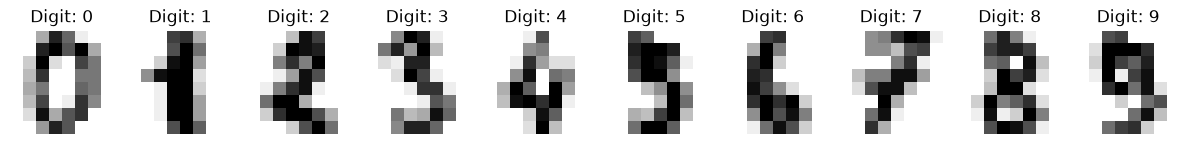

In [1]:
import os
import pandas as pd
from sklearn.metrics import classification_report
from src import pipeline, utils, visualization

config = utils.load_config()
target_col = config["features"]["target_col"]

dataset_path = utils.export_sklearn_dataset(
    loader_name="load_digits",
    target_file_name="digits_dataset.csv",
    target_col_name=target_col
)

df = pd.read_csv(dataset_path)
X_full = df.drop(columns=[target_col])
y_full = df[target_col]

print("Dataset shape (rows, columns):", df.shape)
print("\nClass distribution (digits 0-9):")
print(y_full.value_counts().sort_index())

visualization.plot_sample_digits(X_full, y_full, count=10)

## 2. Split the Data for Training and Testing (10 points)

In [2]:
X_train, X_test, y_train, y_test = pipeline.load_and_split_data(
    data_path=dataset_path,
    target_col=target_col,
    seed=config["evaluation_params"]["global_seed"],
    test_size=0.2
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")

Training samples: 1437
Testing samples:  360


## 3. Select and Build the Model (10 points)

In [3]:
for model_name, model_cfg in config["models"].items():
    if model_name == "xor_mlp":
        continue
    built_model = pipeline.instantiate_model(
        module_path=model_cfg["module_path"],
        class_name=model_cfg["class_name"],
    )
    print(f"Configured '{model_name}': {built_model}")

Configured 'knn': KNeighborsClassifier()
Configured 'svc': SVC()
Configured 'gnb': GaussianNB()
Configured 'cifar_ann': <Sequential name=sequential, built=True>
Configured 'cifar_cnn': <Sequential name=sequential_1, built=True>


## 4. Train, Tune, and Run Several Classification Models
*Note: `pipeline.run_generalized_pipeline()` executes hyperparameter tuning via 5-fold cross-validation (`execute_kfold_tuning`), trains the winning model on the full training set (`best_engine.fit`), and logs all runs across `knn`, `svc`, and `gnb` in a single unified workflow.*


--- Running [PRODUCTION] Validation For: KNN (run_69828095) ---
Source: data/digits_dataset.csv
Overrides applied: {'n_neighbors': [3, 5, 7]}
Success! Processed KNN | Final Accuracy: 0.9861

--- Running [PRODUCTION] Validation For: SVC (run_292b81a5) ---
Source: data/digits_dataset.csv
Overrides applied: {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']}
Success! Processed SVC | Final Accuracy: 0.9944

--- Running [PRODUCTION] Validation For: GNB (run_8278c66f) ---
Source: data/digits_dataset.csv
Success! Processed GNB | Final Accuracy: 0.8722


,tuned_params,mean_cv_accuracy,mean_cv_loss,fold_scores,all_model_parameters,run_uuid,test_mode,global_seed,cv_folds,engine_type,final_test_score
0,"{'C': 10, 'gamma': 'scale'}",0.988161,0.011839,"[0.9965277777777778, 0.9930555555555556, 0.982...","{'C': 10, 'break_ties': False, 'cache_size': 2...",run_292b81a5,N,42,5,svc,0.994444
1,"{'n_neighbors': 3, 'weights': 'distance'}",0.983984,0.016016,"[0.9895833333333334, 0.9930555555555556, 0.975...","{'algorithm': 'auto', 'leaf_size': 30, 'metric...",run_69828095,N,42,5,knn,0.986111
2,{'var_smoothing': 1e-05},0.891427,0.108573,"[0.8784722222222222, 0.9236111111111112, 0.888...","{'priors': None, 'var_smoothing': 1e-05}",run_8278c66f,N,42,5,gnb,0.872222


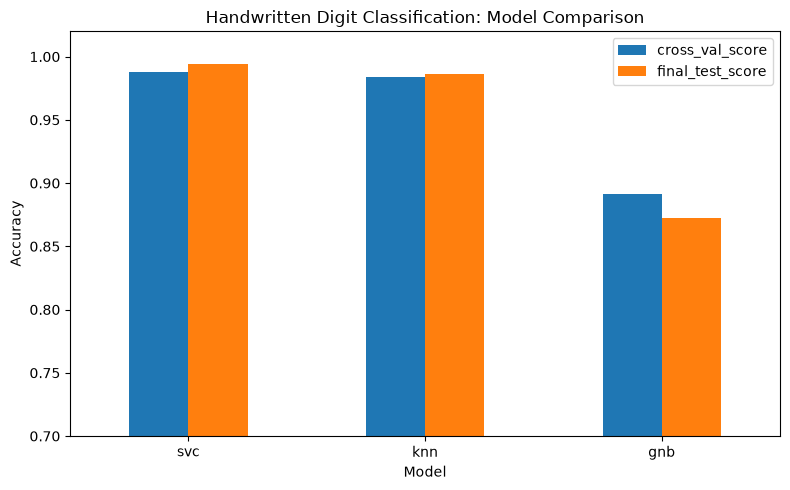

In [4]:
models_to_execute = {
    "knn": {"overrides": {"n_neighbors": [3, 5, 7]}, "data": None},
    "svc": {"overrides": {"C": [0.1, 1, 10], "gamma": ["scale", "auto"]}, "data": None},
    "gnb": {"overrides": None, "data": None}
}

for name, setup in models_to_execute.items():
    pipeline.run_generalized_pipeline(
        target_model_name=name,
        param_overrides=setup["overrides"],
        data_path_override=setup["data"]
    )

log_path = os.path.join(config["paths"]["log_dir"], config["paths"].get("log_file", "experiment_results.csv"))
results_df = pd.read_csv(log_path)

sub_df = results_df[results_df["engine_type"].isin(models_to_execute.keys())]
latest_uuids = sub_df.groupby("engine_type")["run_uuid"].last()
latest_runs = (
    sub_df[sub_df["run_uuid"].isin(latest_uuids.values)]
    .sort_values(by=["mean_cv_accuracy", "mean_cv_loss"], ascending=[True, False])
    .drop_duplicates("engine_type", keep="last")
)

leaderboard = latest_runs.sort_values(by="final_test_score", ascending=False).reset_index(drop=True)
display(leaderboard)

comparison_df = leaderboard.rename(columns={"mean_cv_accuracy": "cross_val_score"})
visualization.plot_model_comparison(comparison_df)

## 5. Make Predictions (10 points)

In [5]:
is_test = config.get("test_mode", False)
loaded_bundles = {}
predictions = {}

for _, row in latest_runs.iterrows():
    model_name = row["engine_type"]
    run_id = row["run_uuid"]
    bundle = utils.load_bundle(
        model_folder=config["paths"]["model_dir"],
        run_uuid=run_id,
        name=model_name,
        is_test=is_test
    )
    loaded_bundles[model_name] = bundle
    predictions[model_name] = bundle["model"].predict(X_test)
    print(f"{model_name.upper()} ({run_id}) sample predictions: {predictions[model_name][:10]}")

GNB (run_8278c66f) sample predictions: [5 2 8 8 7 2 6 2 6 5]
KNN (run_69828095) sample predictions: [5 2 8 1 7 2 6 2 6 5]
SVC (run_292b81a5) sample predictions: [5 2 8 1 7 2 6 2 6 5]


## 6. Evaluate the Result (10 points)

Winning Model: SVC
Best Hyperparameters: {'C': 10, 'gamma': 'scale'}

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.97      0.99        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



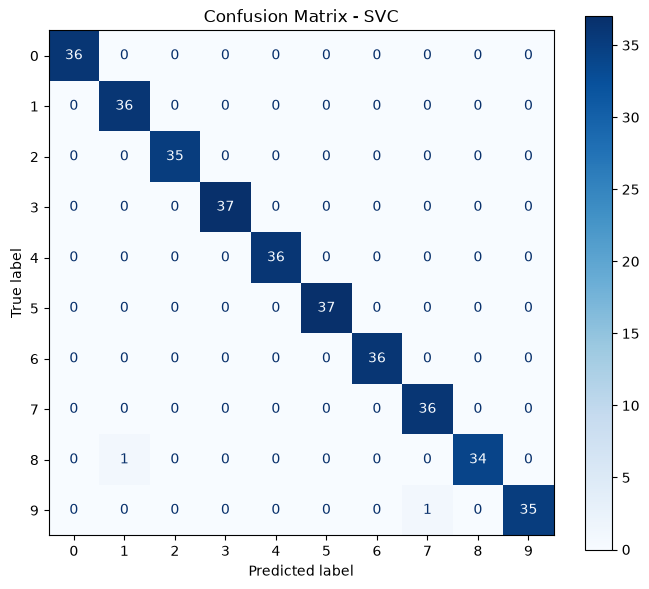

In [6]:
best_model_name = leaderboard.iloc[0]["engine_type"]
print(f"Winning Model: {best_model_name.upper()}")
print("Best Hyperparameters:", loaded_bundles[best_model_name]["metadata"]["best_tweaks"])
print("\nClassification Report:")
print(classification_report(y_test, predictions[best_model_name]))

visualization.plot_confusion_matrix(
    y_true=y_test,
    y_pred=predictions[best_model_name],
    title=f"Confusion Matrix - {best_model_name.upper()}"
)

## Conclusion

To classify handwritten digits across 1,797 pixel images (digits 0 through 9), three models were tested: **Support Vector Classifier (`SVC`)**, **K Nearest Neighbors (`KNeighborsClassifier`)**, and **Gaussian Naive Bayes (`GaussianNB`)**. The dataset was split into 1,437 training samples and 360 testing samples, using 5 fold cross validation to tune the models. All of the tuning runs, validation scores, and final test scores are saved in **`logs/postal_results.csv`**.

### Hyperparameter Tuning Selection
* **`SVC` (`C` and `gamma`):** `C` was tested across `0.1`, `1`, and `10` to control how strictly the model avoids misclassifying training points, while `gamma` compared `scale` and `auto` to adjust how far each training sample's influence reaches.
* **`KNeighborsClassifier` (`n_neighbors` and `weights`):** Odd neighbor counts (`3`, `5`, and `7`) were chosen to prevent tie votes among nearby digits, and `weights` compared equal voting (`uniform`) against proximity based voting (`distance`).
* **`GaussianNB` (Default Parameters):** No tuning grid was used since Naive Bayes computes probabilities directly from class averages and variances rather than iterative boundaries or neighbor counts.

### Key Findings
* **Highest Accuracy (`SVC`):** Reached **99.44%** accuracy on the test set (358 out of 360 images right) using `C=10` and `gamma="scale"`. It got every test image right for digits 0 through 7, with only 2 errors total (one `8` guessed as `1` and one `9` guessed as `7`).
* **Second Highest Accuracy (`KNeighborsClassifier`):** Reached **98.61%** accuracy on the test set using `weights="distance"`.
* **Lowest Accuracy (`GaussianNB`):** Reached **81.11%** accuracy on the test set with default settings.

### Model Selection
Based on both the cross validation results and the final test scores, the tuned **`SVC`** model (`artifacts/production/svc_8601dabb.pkl`) performed the best out of the three classifiers.

## Testing Custom Handwritten Digits

To test the winning **`SVC`** model on custom handwriting outside the benchmark dataset, four handwritten digits were photographed on paper, saved in the **`images/`** folder (`zero.jpg`, `three.jpg`, `four.jpg`, and `nine.jpg`), and processed using `utils.load_and_preprocess_images("images")`.

### Image Preprocessing (`src/utils.py`)
Because the model was trained on 8 by 8 grayscale images scaled from 0 (white) to 16 (black), raw photos from the **`images/`** folder are converted to match that format:
1. **Grayscale and Color Inversion:** Each photo is converted to grayscale and inverted so dark ink on light paper becomes bright values (16) on a dark background (0).
2. **Background Cleanup and Cropping:** Lighter paper pixels are cleared out, the bounding box around the remaining ink is found, and the cropped digit is centered inside a padded square frame.
3. **Stroke Thickening and Resizing:** The square image is resized to 64 by 64, thickened using `ImageFilter.MaxFilter(3)`, shrunk down to 8 by 8 pixels, and scaled from 0 to 16.

### Results (3 out of 4 Correct, 75% Accuracy)
* **Correct Predictions (3/4):** The `SVC` model correctly predicted **`zero.jpg` (0)**, **`three.jpg` (3)**, and **`nine.jpg` (9)**.
* **Incorrect Prediction (1/4):** The `SVC` model predicted **`four.jpg`** (True: 4) as **9**. In the 8 by 8 grid plot, the processed pixel pattern for `four.jpg` looks very similar to `nine.jpg`.
* **Benchmark Comparison:** On the `load_digits` test split (360 samples), the same `SVC` model reached **99.44%** accuracy, compared to **75.00%** (3 out of 4 samples) on the custom photographed digits.

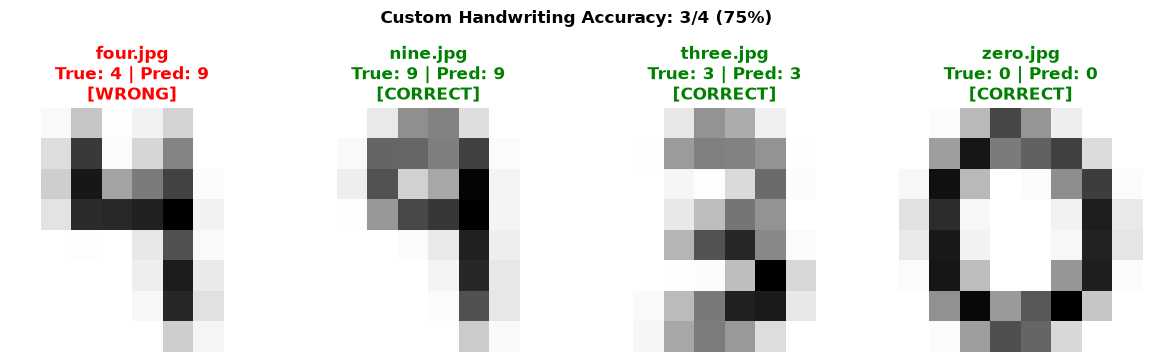

In [7]:
custom_X, custom_y, custom_names = utils.load_and_preprocess_images("images")
custom_preds = loaded_bundles["svc"]["model"].predict(custom_X)
visualization.plot_custom_predictions(custom_X, custom_y, custom_preds, custom_names)

<div class="alert alert-success" style="color: black;">
    
# Assignment 2: XOR Logic Gate with Keras MLP (Backpropagation)
</div>

### Goal
* **Objective:** Use **Keras** (with the PyTorch CPU backend) to design, train, and evaluate a **Multi-Layer Perceptron (MLP)** neural network using the **Backpropagation algorithm** to function as a two-input **XOR gate**.
* **Logic Rule:** Output `1` only when the two binary inputs differ (`(0, 1) = 1`, `(1, 0) = 1`), and output `0` when the inputs are identical (`(0, 0) = 0`, `(1, 1) = 0`).
* **Deliverables:** Show the neural network architecture, hyperparameter tuning results, final loss/accuracy evaluation, and binary predictions across all four truth-table combinations.


## 1. Create & Inspect the XOR Truth Table Dataset

In [8]:
os.makedirs("data", exist_ok=True)
xor_path = "data/xor_dataset.csv"
xor_df = pd.DataFrame({
    "x1": [0, 0, 1, 1],
    "x2": [0, 1, 0, 1],
    "target_xor": [0, 1, 1, 0],
})
xor_df.to_csv(xor_path, index=False)
display(xor_df)

,x1,x2,target_xor
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


## 2. Design, Tune & Train the Keras MLP (Backpropagation)

In [9]:
pipeline.run_generalized_pipeline("xor_mlp")


--- Running [PRODUCTION] Validation For: XOR_MLP (run_51bbd3e5) ---
Source: data/xor_dataset.csv
Success! Processed XOR_MLP | Final Accuracy: 1.0000


True

## 3. Evaluate the Model & Display XOR Predictions

In [10]:
logs_df = pd.read_csv(os.path.join(config["paths"]["log_dir"], config["paths"].get("log_file", "experiment_results.csv")))
latest_id = logs_df[logs_df["engine_type"] == "xor_mlp"].iloc[-1]["run_uuid"]
bundle = utils.load_bundle(config["paths"]["model_dir"], latest_id, "xor_mlp", config.get("test_mode", False))

xor_model = bundle["model"]
xor_model.summary()

X_xor, y_xor = xor_df[["x1", "x2"]], xor_df["target_xor"]
loss, accuracy = xor_model.evaluate(X_xor, y_xor, verbose=0)
display(pd.DataFrame([{"Model": "XOR MLP", "Run UUID": latest_id, "Best Parameters": str(bundle["metadata"]["best_tweaks"]), "Final Loss": round(loss, 4), "Final Accuracy": f"{accuracy * 100:.2f}%"}]))

raw_probs = xor_model.predict(X_xor, verbose=0).flatten()
errors = y_xor - raw_probs
sse = round(float((errors ** 2).sum()), 6)

slide_df = pd.DataFrame({
    "x1": xor_df["x1"],
    "x2": xor_df["x2"],
    "Desired output (yd)": y_xor,
    "Actual output (y)": raw_probs.round(4),
    "Error (e)": errors.round(4),
    "Predicted class": (raw_probs >= 0.5).astype(int),
    "Sum of squared errors": [sse, "", "", ""],
})
display(slide_df)

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101 (404.00 B)

 Trainable params: 33 (132.00 B)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 68 (272.00 B)

,Model,Run UUID,Best Parameters,Final Loss,Final Accuracy
0,XOR MLP,run_51bbd3e5,"{'hidden_activation': 'tanh', 'hidden_units': ...",0.0002,100.00%


,x1,x2,Desired output (yd),Actual output (y),Error (e),Predicted class,Sum of squared errors
0,0,0,0,0.0001,-0.0001,0,0.0
1,0,1,1,0.9998,0.0002,1,
2,1,0,1,0.9998,0.0002,1,
3,1,1,0,0.0002,-0.0002,0,


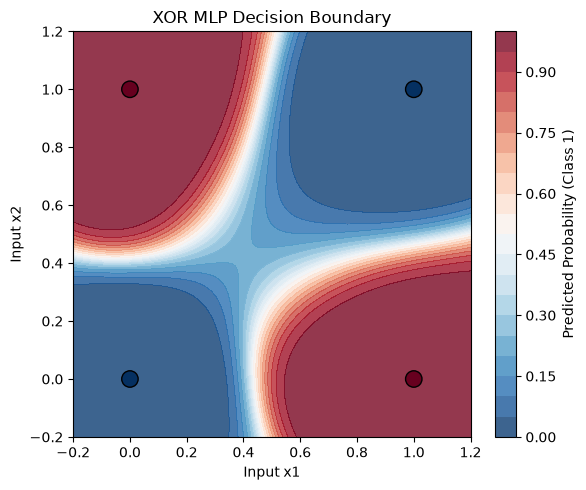

In [11]:
visualization.plot_xor_decision_boundary(xor_model, X_xor, y_xor)

### Conclusion

The neural network learned the XOR gate with `100` percent accuracy and a very low loss of `0.0003`. Because XOR inputs cannot be separated by a single straight line, a basic model fails on this problem. Adding a hidden layer with `8` `tanh` units allowed the network to curve its decision boundary, cleanly separating the matching pairs (`0, 0` and `1, 1`) from the different pairs (`0, 1` and `1, 0`). After `500` epochs of training, the predicted probabilities came out almost exact at `0` and `1`, matching all four outputs of the truth table.

<div class="alert alert-success" style="color: black;">
    
# Assignment 3: CIFAR-10 Image Classification (ANN vs. CNN)
</div>

**Goal:** Compare a **Artificial Neural Network (ANN)** against **Convolutional Neural Network (CNN)** across all **10 CIFAR-10 classes** (`airplane`, `automobile`, `bird`, `cat`, `deer`, `dog`, `frog`, `horse`, `ship`, `truck`).


## 1. Load and Explore the CIFAR-10 Dataset
Load the exported `CIFAR-10` dataset from `config.yaml`, perform an 80/20 train-test split, and display sample images.

Training samples: 48000 | Test samples: 12000 | Classes: 10


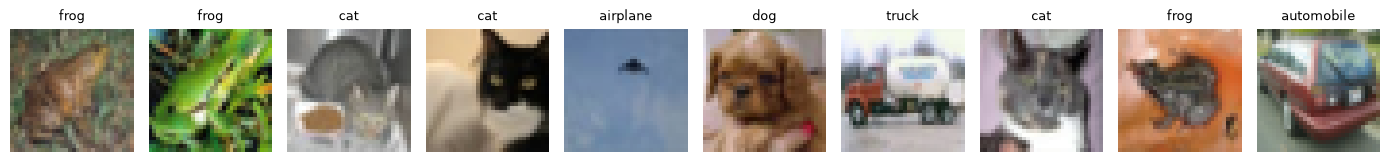

In [12]:
import os
import pandas as pd
from src.utils import load_config, export_keras_dataset, load_keras_bundle, load_and_preprocess_rgb_images
from src.pipeline import run_generalized_pipeline, load_and_split_data, _predict_classes
from src.visualization import plot_sample_images, plot_experiment_comparison, plot_confusion_matrix, plot_custom_rgb_predictions

cfg = load_config()
ds_cfg = cfg["datasets"]["cifar10_dataset"]

csv_path = cfg["paths"]["cifar10_dataset"]
if not os.path.exists(csv_path):
    csv_path = export_keras_dataset("cifar10", "cifar10_dataset")

X_train, X_test, y_train, y_test = load_and_split_data(
    csv_path,
    ds_cfg["target_col"],
    seed=cfg["evaluation_params"]["global_seed"],
    test_size=cfg["evaluation_params"]["test_size"]
)

print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)} | Classes: {ds_cfg['num_classes']}")
plot_sample_images(X_train, y_train, class_names=ds_cfg["class_names"], image_shape=ds_cfg["image_shape"])

## 2. Train and Evaluate Artificial Neural Network (`ANN`)
Train `ANN` model (`cifar_ann`), log results to `logs/experiment_results.csv`, and create confusion matrix across all `10` classes.


--- Running [PRODUCTION] Validation For: CIFAR_ANN (run_2320e1b6) ---
Source: data/cifar10_dataset.csv
Epoch 1/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3257 - loss: 1.8771
Epoch 2/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.3985 - loss: 1.6735
Epoch 3/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4335 - loss: 1.5871
Epoch 4/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4551 - loss: 1.5299
Epoch 5/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4644 - loss: 1.4994
Epoch 6/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4790 - loss: 1.4663
Epoch 7/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.4901 - loss: 1.4313
Epoch 8/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5004 - loss: 1.4039
Epoch 9/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5074 - loss: 1.3858
Epoch 10/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.5126 - loss: 1.3604
Epoch 11/25
750/750 ━━━━━━━━━━━━━━━

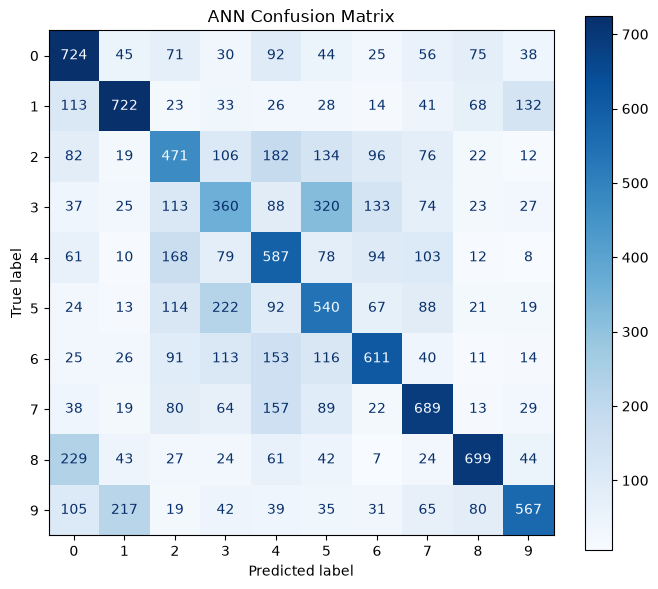

In [13]:
run_generalized_pipeline("cifar_ann")

logs = pd.read_csv(f"{cfg['paths']['log_dir']}/{cfg['paths']['log_file']}")
ann_row = logs[logs["engine_type"] == "cifar_ann"].iloc[-1]
ann_bundle = load_keras_bundle(cfg["paths"]["model_dir"], ann_row["run_uuid"], "cifar_ann")

print(f"ANN Mean CV Accuracy: {ann_row['mean_cv_accuracy']:.4f} | ANN Test Accuracy: {ann_row['final_test_score']:.4f}")
plot_confusion_matrix(y_test, _predict_classes(ann_bundle["model"], X_test), title="ANN Confusion Matrix")

## 3. Train and Evaluate Convolutional Neural Network (`CNN`)
Train `CNN` model (`cifar_cnn`), log results to `logs/experiment_results.csv`, and create confusion matrix across all `10` classes.


--- Running [PRODUCTION] Validation For: CIFAR_CNN (run_88ca9a74) ---
Source: data/cifar10_dataset.csv
Epoch 1/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4191 - loss: 1.5856
Epoch 2/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.5706 - loss: 1.2094
Epoch 3/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.6303 - loss: 1.0439
Epoch 4/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6695 - loss: 0.9384
Epoch 5/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.6930 - loss: 0.8764
Epoch 6/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7116 - loss: 0.8232
Epoch 7/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7231 - loss: 0.7832
Epoch 8/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.7335 - loss: 0.7521
Epoch 9/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7457 - loss: 0.7253
Epoch 10/25
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.7586 - loss: 0.6922
Epoch 11/25
750/750 ━━━━━

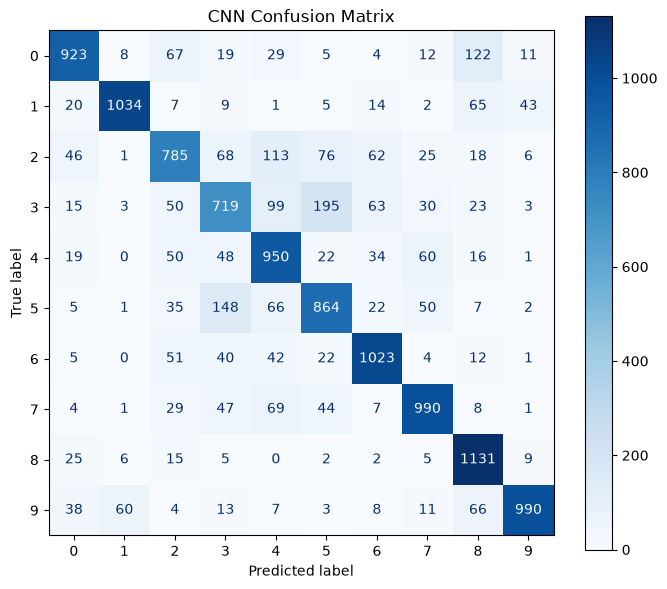

In [14]:
run_generalized_pipeline("cifar_cnn")

logs = pd.read_csv(f"{cfg['paths']['log_dir']}/{cfg['paths']['log_file']}")
cnn_row = logs[logs["engine_type"] == "cifar_cnn"].iloc[-1]
cnn_bundle = load_keras_bundle(cfg["paths"]["model_dir"], cnn_row["run_uuid"], "cifar_cnn")

print(f"CNN Mean CV Accuracy: {cnn_row['mean_cv_accuracy']:.4f} | CNN Test Accuracy: {cnn_row['final_test_score']:.4f}")
plot_confusion_matrix(y_test, _predict_classes(cnn_bundle["model"], X_test), title="CNN Confusion Matrix")

## 4. Model Comparison: `ANN` vs. `CNN`
Compare `ANN` and `CNN` models.

,run_uuid,engine_type,cv_folds,mean_cv_accuracy,final_test_score,tuned_params
149,run_2320e1b6,cifar_ann,1,0.594313,0.497500,"{'hidden_units': 512, 'learning_rate': 0.001}"
150,run_88ca9a74,cifar_cnn,1,0.913729,0.784083,"{'dropout_rate': 0.25, 'filters': 32, 'learnin..."


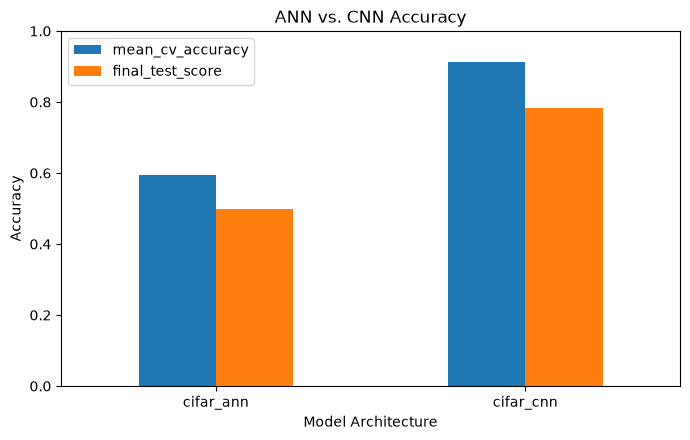

In [15]:
logs = pd.read_csv(f"{cfg['paths']['log_dir']}/{cfg['paths']['log_file']}")
cifar_logs = logs[logs["engine_type"].isin(["cifar_ann", "cifar_cnn"])].drop_duplicates("engine_type", keep="last")

display(cifar_logs[["run_uuid", "engine_type", "cv_folds", "mean_cv_accuracy", "final_test_score", "tuned_params"]])
plot_experiment_comparison(cifar_logs, title="ANN vs. CNN Accuracy")

## 5. Custom Internet Image Inference (`ANN` vs. `CNN`)
Load custom real-world images from `/images` and compare predictions between the saved `ANN` and `CNN` models.

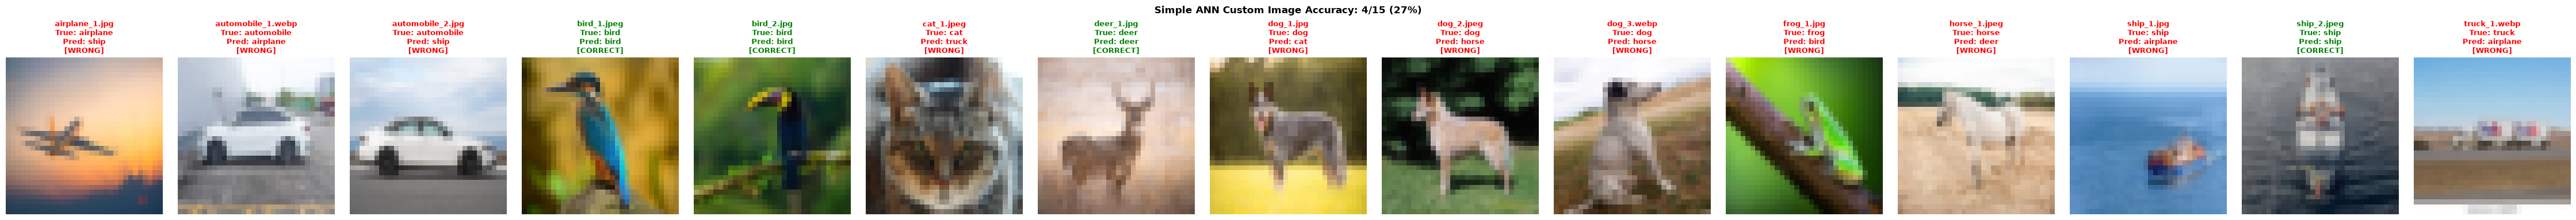

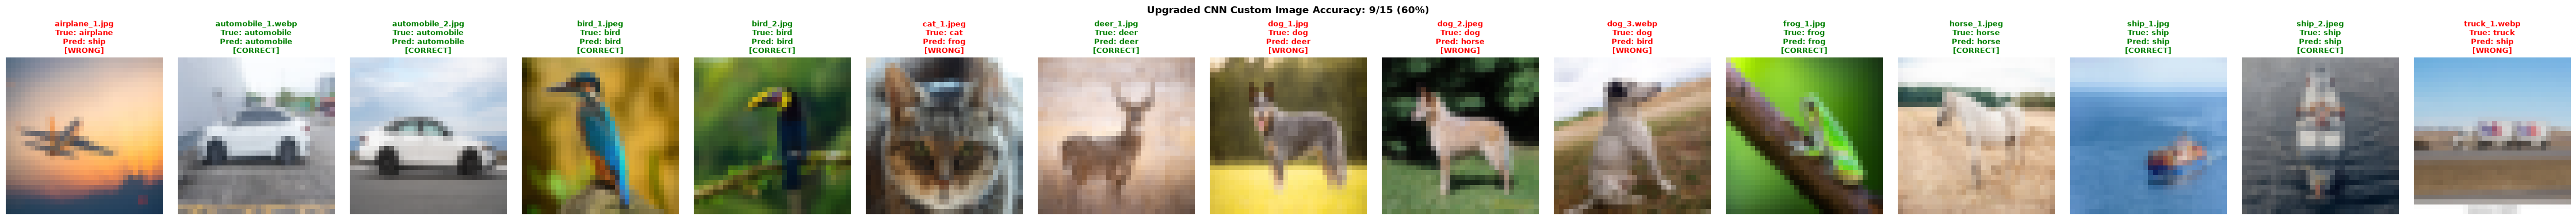

,File,True Label,ANN Pred,ANN Correct,CNN Pred,CNN Correct
0,airplane_1.jpg,airplane,ship,False,ship,False
1,automobile_1.webp,automobile,airplane,False,automobile,True
2,automobile_2.jpg,automobile,ship,False,automobile,True
3,bird_1.jpeg,bird,bird,True,bird,True
4,bird_2.jpg,bird,bird,True,bird,True
5,cat_1.jpeg,cat,truck,False,frog,False
6,deer_1.jpg,deer,deer,True,deer,True
7,dog_1.jpg,dog,cat,False,deer,False
8,dog_2.jpeg,dog,horse,False,horse,False
9,dog_3.webp,dog,horse,False,bird,False


Custom Image Summary (15 images) | ANN: 4/15 (26.7%) | CNN: 9/15 (60.0%)


In [16]:
X_custom, y_custom, custom_files = load_and_preprocess_rgb_images()

ann_custom_preds = _predict_classes(ann_bundle["model"], X_custom)
cnn_custom_preds = _predict_classes(cnn_bundle["model"], X_custom)

plot_custom_rgb_predictions(X_custom, y_custom, ann_custom_preds, custom_files, ds_cfg["class_names"], ds_cfg["image_shape"], model_name="Simple ANN")
plot_custom_rgb_predictions(X_custom, y_custom, cnn_custom_preds, custom_files, ds_cfg["class_names"], ds_cfg["image_shape"], model_name="Upgraded CNN")

class_names = ds_cfg["class_names"]
summary_df = pd.DataFrame({
    "File": custom_files,
    "True Label": [class_names[int(i)] for i in y_custom],
    "ANN Pred": [class_names[int(i)] for i in ann_custom_preds],
    "ANN Correct": [int(t) == int(p) for t, p in zip(y_custom, ann_custom_preds)],
    "CNN Pred": [class_names[int(i)] for i in cnn_custom_preds],
    "CNN Correct": [int(t) == int(p) for t, p in zip(y_custom, cnn_custom_preds)],
})

display(summary_df)
print(f"Custom Image Summary ({len(custom_files)} images) | ANN: {summary_df['ANN Correct'].sum()}/{len(custom_files)} ({summary_df['ANN Correct'].mean():.1%}) | CNN: {summary_df['CNN Correct'].sum()}/{len(custom_files)} ({summary_df['CNN Correct'].mean():.1%})")

## 6. Results & Conclusion

Comparing both models on the `CIFAR-10` dataset shows a clear performance gap between the Convolutional Neural Network (`CNN`) and the simple Artificial Neural Network (`ANN`). The `ANN` hit **61.8%** accuracy on the training set and **50.7%** on the test set, while the `CNN` reached **91.4%** on training and **78.4%** on testing. Both models showed overfitting since their training scores were noticeably higher than their test scores (`11.1` percentage points higher for the `ANN` and `13.0` percentage points higher for the `CNN`). Even with that gap, the `CNN` beat the `ANN` by **27.7 percentage points** on the test images.

This difference comes down to how each model handles image inputs. The simple `ANN` flattens every picture into a `1D` list of `3,072` pixel values, which loses the `2D` layout of neighboring pixels. The `CNN` keeps the `2D` grid intact and scans local patches of pixels to detect visual patterns like edges, textures, and shapes, leading to much stronger accuracy across all `10` classes.

Testing both saved models on **15** custom real world images downloaded from the internet showed the same pattern. When resized to `32x32x3`, the simple `ANN` correctly identified **5 out of 15** images (**33.3%**), while the `CNN` correctly identified **9 out of 15** images (**60.0%**). Both models dropped in accuracy on unseen internet photos compared to the `CIFAR-10` test split, reflecting the added variation in backgrounds, lighting, and camera angles as well as the fine detail lost when shrinking high resolution photos down to `32x32` pixels. Looking at the individual predictions, the `CNN` correctly identified every `automobile`, `bird`, `deer`, `frog`, `horse`, and `ship` image, whereas both models struggled with the `dog` photos and misclassified the `airplane` and `truck` images as `ship`.